# Stage 1 · Inspecting the pain EEG pilot

**Goal:** make sure we can read the raw signals and tell what was delivered, when it was delivered, and what the participant reported. We'll use the data structure and quality checks to guide the research question.

The pilot uses [OpenNeuro ds008349 v2.0.1](https://openneuro.org/datasets/ds008349/versions/2.0.1), participants 086, 089 and 092, and their rated heat, rated sound and eyes-open rest runs. The local download manifest records the source and checksums. The published files are read as-is.

Work down the notebook one cell at a time with **Shift+Enter**. Start with the plotted example, then use the tables to check whether what you saw holds across the pilot.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

# This notebook lives beside the data folder.
root = Path("data/raw/ds008349-2.0.1")
subjects = ("086", "089", "092")
tasks = {
    "thermalactive": "Rated heat",
    "audioactive": "Rated sound",
    "restingopen": "Eyes-open rest",
}
assert (root / "pilot-download-manifest.json").is_file(), "Open the notebook from the project folder."

## 1. Open one recording and look at the EEG

A BrainVision recording has a header ( .vhdr ), a signal file ( .eeg ), and a marker file ( .vmrk ). Pass the **header** to MNE, which opens the linked files. Use the dataset's channel table to select scalp EEG. The recording also contains eye, heart, skin-conductance and task signals. Some auxiliary waveforms would otherwise be picked up as EEG by the BrainVision reader's defaults.

EEG records a voltage difference relative to a reference electrode. These runs were recorded with FCz as reference. MNE returns EEG in volts, so multiplying by one million displays microvolts. The rating and stimulus channels use task units, and the thermode uses degrees Celsius. Leave those channels in their original units.

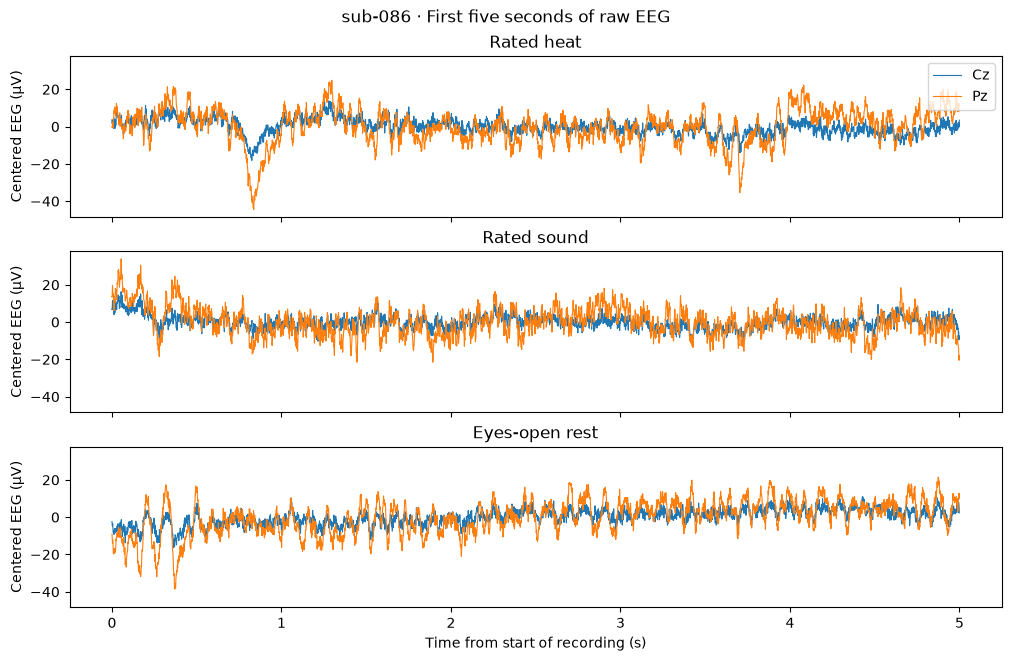

Sampling rate: 1,000 Hz (1 ms per sample)
Scalp EEG channels: 63


,Run,Cz mean (µV),Pz mean (µV)
0,Rated heat,2137.1,5485.0
1,Rated sound,2220.8,5701.5
2,Eyes-open rest,1541.3,4077.1


In [2]:
def open_recording(subject, task):
    # Construct the file names from the participant and task IDs.
    folder = root / f"sub-{subject}" / "eeg"
    prefix = folder / f"sub-{subject}_task-{task}"
    channel_table = pd.read_csv(f"{prefix}_channels.tsv", sep="\t")

    # Set EOG channels explicitly and preserve other auxiliary data as misc.
    eeg_names = channel_table.loc[channel_table["type"] == "EEG", "name"].tolist()
    eog_names = channel_table.loc[channel_table["type"] == "EOG", "name"].tolist()
    misc_names = channel_table.loc[~channel_table["type"].isin(["EEG", "EOG"]), "name"].tolist()
    raw = mne.io.read_raw_brainvision(
        f"{prefix}_eeg.vhdr",
        eog=eog_names,
        misc=misc_names,
        preload=False,
        ignore_marker_types=True,
        verbose="WARNING",
    )
    return prefix, raw, eeg_names


# Load just the first five seconds from each run for one participant.
figure, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True, sharey=True, layout="constrained")
offsets = []
for task, axis in zip(tasks, axes):
    _, raw, eeg_names = open_recording("086", task)
    sfreq = raw.info["sfreq"]
    signal, time = raw.get_data(picks=["Cz", "Pz"], stop=int(5 * sfreq), return_times=True)
    microvolts = signal * 1e6
    mean_voltage = microvolts.mean(axis=1)
    offsets.append({"Run": tasks[task], "Cz mean (µV)": mean_voltage[0], "Pz mean (µV)": mean_voltage[1]})
    # Subtract each trace's mean for display only so small changes are visible.
    axis.plot(time, (microvolts - mean_voltage[:, None]).T, linewidth=0.8)
    axis.set(title=tasks[task], ylabel="Centered EEG (µV)")
axes[0].legend(["Cz", "Pz"], loc="upper right")
axes[-1].set_xlabel("Time from start of recording (s)")
figure.suptitle("sub-086 · First five seconds of raw EEG")
plt.show()

print(f"Sampling rate: {sfreq:,.0f} Hz ({1000 / sfreq:g} ms per sample)")
print(f"Scalp EEG channels: {len(eeg_names)}")
display(pd.DataFrame(offsets).round(1))

**How to read it.** Cz and Pz are two scalp sites. Their stored voltages have large offsets. The table shows those offsets, and the plot subtracts each trace's mean for display so you can see smaller fluctuations on a shared scale. The raw data and subsequent checks use the original values. Look for slow drift, sharp transients, or stretches with little signal.

## 2. Check the event clock and rating clock

The event TSV gives onsets in seconds and sample indices starting at zero. Multiplying seconds by samples per second should recover the sample index up to rounding. MNE has already converted the BrainVision markers to the same zero-based time axis. Compare labels and times against the TSV.

The rated runs also contain a separate rating log, with a nominal rate of 50 Hz and explicit timestamps. Map each log timestamp to the nearest EEG sample and compare it with the embedded rating. This checks how the released files align on the EEG clock. It cannot establish how long a participant took to feel or report a change.

In [3]:
inventory_rows, event_rows, rating_rows = [], [], []

for subject in subjects:
    for task, task_name in tasks.items():
        prefix, raw, eeg_names = open_recording(subject, task)
        sfreq = raw.info["sfreq"]
        events = pd.read_csv(f"{prefix}_events.tsv", sep="\t")
        rating = raw.get_data(picks=["rating"])[0]

        inventory_rows.append({
            "Subject": subject, "Run": task_name, "EEG channels": len(eeg_names),
            "Hz": sfreq, "Seconds": (raw.n_times - 1) / sfreq,
            "Nonfinite ratings": int((~np.isfinite(rating)).sum()),
            "Rating minimum": rating.min(), "Rating maximum": rating.max(),
            "999 values": int((rating == 999).sum()),
        })

        # Compare the TSV's two ways of storing event time.
        samples = events["sample"].to_numpy(dtype=int)
        from_onsets = np.rint(events["onset"].to_numpy() * sfreq).astype(int)
        assert ((samples >= 0) & (samples < raw.n_times)).all()
        labels = events["trial_type"].tolist()
        notes = dict(zip(raw.annotations.description, raw.annotations.onset))
        marker_ms = [
            abs(notes[label] - onset) * 1000
            for label, onset in zip(labels, events["onset"])
            if label in notes
        ]
        trigger_ms = np.nan
        if "trigger_temp" in events:
            trigger_ms = (events["trigger_temp"] - events["sample"]).abs().max() * 1000 / sfreq
        event_rows.append({
            "Subject": subject, "Run": task_name, "Events": len(events),
            "Matching labels": len(marker_ms),
            "Onset vs sample max (ms)": np.max(np.abs(from_onsets - samples)) * 1000 / sfreq,
            "TSV vs BrainVision max (ms)": round(max(marker_ms), 3) if marker_ms else np.nan,
            "Temp trigger vs event max (ms)": trigger_ms,
        })

        if task == "restingopen":
            continue

        # Round the separate log time to the nearest EEG sample.
        log = pd.read_csv(f"{prefix}_stim.tsv.gz", sep="\t")
        log_time = log["times (s)"].to_numpy()
        assert (np.diff(log_time) > 0).all()
        nearest = np.rint(log_time * sfreq).astype(int)
        inside = (nearest >= 0) & (nearest < raw.n_times)
        matches = np.isclose(rating[nearest[inside]], log.loc[inside, "rating"], rtol=0, atol=1e-6)
        rating_rows.append({
            "Subject": subject, "Run": task_name, "Log rows": len(log),
            "In EEG time range": int(inside.sum()), "Ratings matched": int(matches.sum()),
        })

inventory = pd.DataFrame(inventory_rows)
event_check = pd.DataFrame(event_rows)
rating_check = pd.DataFrame(rating_rows)
display(inventory.round(3), event_check, rating_check)

,Subject,Run,EEG channels,Hz,Seconds,Nonfinite ratings,Rating minimum,Rating maximum,999 values
0,086,Rated heat,63,1000.0,500.000,0,0.0,170.0,0
1,086,Rated sound,63,1000.0,490.000,0,0.0,200.0,0
2,086,Eyes-open rest,63,1000.0,300.001,0,-1.0,-1.0,0
3,089,Rated heat,63,1000.0,500.000,0,0.0,200.0,0
4,089,Rated sound,63,1000.0,490.000,0,0.0,200.0,0
5,089,Eyes-open rest,63,1000.0,300.004,0,-1.0,-1.0,0
6,092,Rated heat,63,1000.0,500.000,0,0.0,200.0,0
7,092,Rated sound,63,1000.0,490.000,0,0.0,184.0,0
8,092,Eyes-open rest,63,1000.0,300.001,0,-1.0,-1.0,0


,Subject,Run,Events,Matching labels,Onset vs sample max (ms),TSV vs BrainVision max (ms),Temp trigger vs event max (ms)
0,086,Rated heat,10,10,0.0,1.0,41.0
1,086,Rated sound,10,10,0.0,0.0,NaN
2,086,Eyes-open rest,1,1,0.0,0.0,NaN
3,089,Rated heat,10,10,1.0,0.0,31.0
4,089,Rated sound,10,10,0.0,0.0,NaN
5,089,Eyes-open rest,1,1,0.0,0.0,NaN
6,092,Rated heat,10,10,0.0,1.0,31.0
7,092,Rated sound,10,10,0.0,0.0,NaN
8,092,Eyes-open rest,1,1,0.0,0.0,NaN


,Subject,Run,Log rows,In EEG time range,Ratings matched
0,086,Rated heat,25000,25000,25000
1,086,Rated sound,24500,24500,24500
2,089,Rated heat,25000,25000,25000
3,089,Rated sound,24500,24500,24500
4,092,Rated heat,25000,25000,25000
5,092,Rated sound,24500,24500,24500


**How to read it.** The run duration is the time of the last sample. Rest uses **−1** as the missing rating value. The active runs use a different numerical scale from the laser datasets we compared, so keep the released rating units and check any scale anchors before rescaling. The dataset metadata flag **999** as a missing-rating placeholder in another run. An event table duration of zero means the marker marks a point in time. Use the stimulus and temperature traces to find ramps and plateaus.

## 3. See what changed at an event

This example uses the second heat event. The three panels share one time axis. The dotted line is the event time, and the shading shows a deliberately simple inspection window 25–35 seconds after that event. We use it below to check repeated segments at the same programmed level. The plot shows why an event, a physical temperature change, and a reported change in pain are distinct.

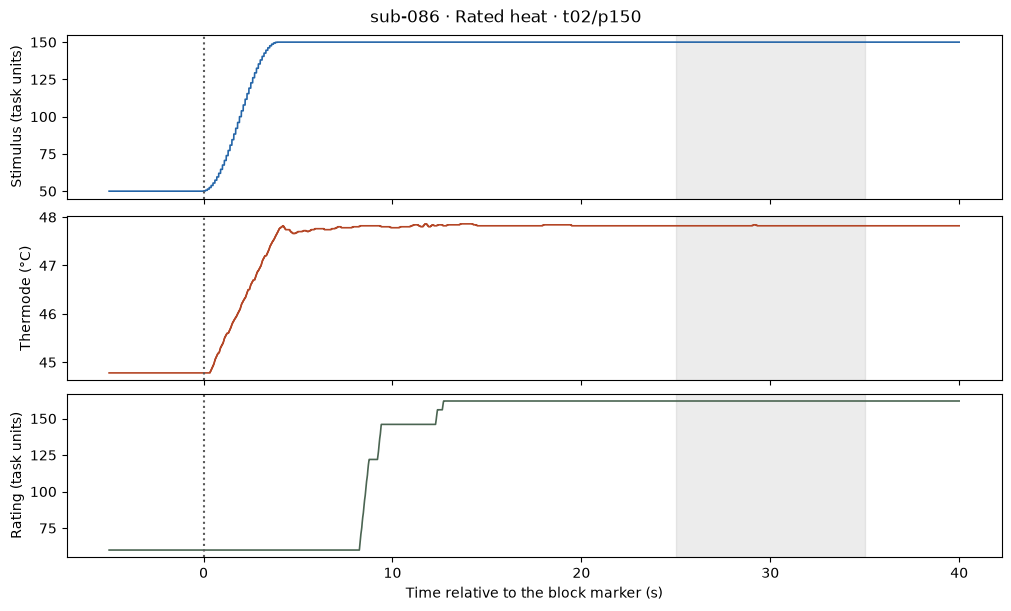

In [4]:
prefix, raw, _ = open_recording("086", "thermalactive")
events = pd.read_csv(f"{prefix}_events.tsv", sep="\t")
event = events.iloc[1]
sfreq = raw.info["sfreq"]

start = max(0, int((event["onset"] - 5) * sfreq))
stop = min(raw.n_times, int((event["onset"] + 40) * sfreq))
traces, times = raw.get_data(
    picks=["stim", "thermode", "rating"], start=start, stop=stop, return_times=True
)
relative_time = times - event["onset"]

figure, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout="constrained")
for axis, trace, label, color in zip(
    axes, traces, ["Stimulus (task units)", "Thermode (°C)", "Rating (task units)"],
    ["#2465a8", "#b44626", "#4b6552"],
):
    axis.plot(relative_time, trace, color=color, linewidth=1.2)
    axis.axvline(0, color="0.35", linestyle=":")
    axis.axvspan(25, 35, color="0.5", alpha=0.15)
    axis.set_ylabel(label)
axes[-1].set_xlabel("Time relative to the block marker (s)")
figure.suptitle(f"sub-086 · Rated heat · {event['trial_type']}")
plt.show()

## 4. Screen the raw EEG across all nine runs

Measure peak-to-peak amplitude, the largest minus the smallest voltage in a window. Use one-second windows to flag where you should look more closely. **150 µV is an inspection threshold chosen for this pilot.** Reference, channel quality, blinks and movement can all affect it. No data are excluded. A window with one channel over the threshold is counted once.

In [5]:
quality_rows = []
for subject in subjects:
    for task, task_name in tasks.items():
        _, raw, eeg_names = open_recording(subject, task)
        # Load one run at a time, using only channels labeled EEG.
        eeg = raw.get_data(picks=eeg_names)
        width = int(raw.info["sfreq"])
        n_windows = raw.n_times // width
        windows = eeg[:, :n_windows * width].reshape(len(eeg_names), n_windows, width)
        peak_to_peak = np.ptp(windows, axis=2) * 1e6
        finite = np.isfinite(peak_to_peak)
        channel_p95 = np.array([
            np.percentile(row[mask], 95) if mask.any() else np.nan
            for row, mask in zip(peak_to_peak, finite)
        ])
        flagged = np.any((peak_to_peak > 150) | ~finite, axis=0)
        quality_rows.append({
            "Subject": subject, "Run": task_name, "1-s windows": n_windows,
            "Windows to inspect (%)": 100 * flagged.mean(),
            "Nonfinite channel-windows": int((~finite).sum()),
            "Zero-range channel-windows": int((peak_to_peak == 0).sum()),
            "Largest channel P95 (µV)": np.nanmax(channel_p95),
            "Channel with largest P95": eeg_names[np.nanargmax(channel_p95)],
        })

quality = pd.DataFrame(quality_rows)
display(quality.round(1))

,Subject,Run,1-s windows,Windows to inspect (%),Nonfinite channel-windows,Zero-range channel-windows,Largest channel P95 (µV),Channel with largest P95
0,086,Rated heat,500,42.4,0,0,217.0,Fp2
1,086,Rated sound,490,23.9,0,0,178.5,T8
2,086,Eyes-open rest,300,12.3,0,0,210.7,Fp2
3,089,Rated heat,500,30.0,0,0,259.5,Fp1
4,089,Rated sound,490,26.5,0,0,241.7,Fp1
5,089,Eyes-open rest,300,21.7,0,0,218.7,Fp1
6,092,Rated heat,500,79.6,0,0,352.9,Fp2
7,092,Rated sound,490,93.5,0,0,418.5,Fp2
8,092,Eyes-open rest,300,47.7,0,0,398.0,Fp1


**How to read it.** Channel P95 is the 95th percentile of that channel's one-second peak-to-peak values. The channel with the largest P95 is a starting point for visual inspection. Flatter, noisier, and shorter artifacts can slip past this simple check. The table cannot classify artifacts or certify clean EEG.

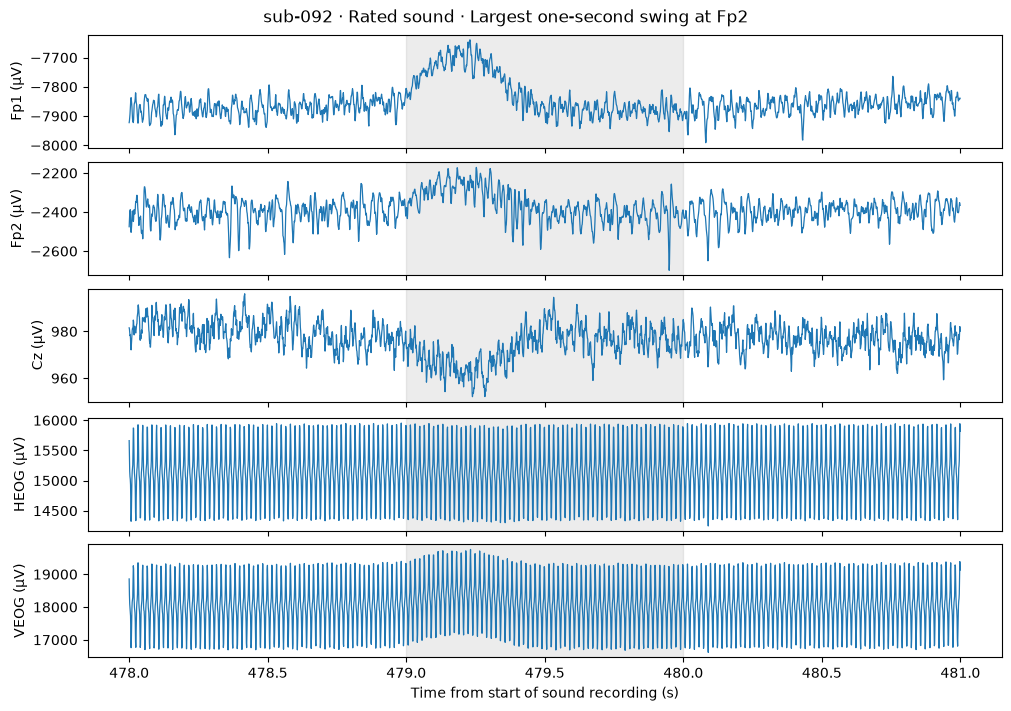

In [6]:
# Find the largest one-second Fp2 swing in the flagged sub-092 sound run.
_, raw, _ = open_recording("092", "audioactive")
width = int(raw.info["sfreq"])
fp2 = raw.get_data(picks=["Fp2"])[0]
seconds = len(fp2) // width
amplitudes = np.ptp(fp2[:seconds * width].reshape(seconds, width), axis=1)
second = int(np.nanargmax(amplitudes))

# Plot the flagged second plus one second of context on each side.
channels = ["Fp1", "Fp2", "Cz", "HEOG", "VEOG"]
start = max(0, (second - 1) * width)
stop = min(raw.n_times, (second + 2) * width)
trace, time = raw.get_data(picks=channels, start=start, stop=stop, return_times=True)
figure, axes = plt.subplots(len(channels), 1, figsize=(10, 7), sharex=True, layout="constrained")
for axis, channel, values in zip(axes, channels, trace):
    axis.plot(time, values * 1e6, linewidth=0.9)
    axis.axvspan(second, second + 1, alpha=0.15, color="0.5")
    axis.set_ylabel(f"{channel} (µV)")
axes[-1].set_xlabel("Time from start of sound recording (s)")
figure.suptitle("sub-092 · Rated sound · Largest one-second swing at Fp2")
plt.show()

Compare the timing of the frontal EEG deflections at Fp1 and Fp2 with the two eye channels and the more central Cz trace. The example has coincident frontal and vertical eye-channel deflections, consistent with a possible eye or movement artifact. Both eye channels also show a fast repeating signal. Inspect more than this one extreme example before deciding how to handle artifacts.

## 5. Check whether ratings vary at comparable stimulus levels

For each labeled stimulus block, summarize the same 10-second inspection window. This gives repeated observations at each programmed level per participant. Read actual temperature from the thermode channel, since the same programmed number can correspond to different temperatures across participants. Compare the median ratings and temperatures within a participant and level. A change in rating at a similar temperature is a reason to look more closely at that question in a larger sample.

The window is a pilot choice. The checks below confirm that it ends before the next event and that the logged stimulus stays at the labeled level throughout it.

In [7]:
blocks = []
for subject in subjects:
    for task in ("thermalactive", "audioactive"):
        prefix, raw, _ = open_recording(subject, task)
        events = pd.read_csv(f"{prefix}_events.tsv", sep="\t")
        sfreq = raw.info["sfreq"]
        for index, event in events.iloc[:-1].iterrows():
            label = event["trial_type"]
            commanded = int(label.split("/p")[1])
            start = int(event["sample"] + 25 * sfreq)
            stop = int(event["sample"] + 35 * sfreq)
            assert stop <= events.iloc[index + 1]["sample"], label
            stimulus, ratings, temps = raw.get_data(
                picks=["stim", "rating", "thermode"], start=start, stop=stop
            )
            assert np.allclose(stimulus, commanded), label
            valid = np.isfinite(ratings) & (ratings >= 0) & (ratings != 999)
            assert valid.any(), f"No valid ratings in {subject} / {task} / {label}"
            blocks.append({
                "Subject": subject, "Run": tasks[task], "Block": label, "Level": commanded,
                "Median rating": np.median(ratings[valid]),
                "Median °C": np.median(temps) if task == "thermalactive" else np.nan,
                "Rating at observed ceiling (%)": 100 * np.mean(ratings[valid] == 200),
            })

block_data = pd.DataFrame(blocks)
example = block_data.query("Subject == '086' and Run == 'Rated heat'")
display(example.round(2))

repeat_check = block_data.groupby(["Subject", "Run", "Level"], as_index=False).agg(
    Repeats=("Block", "size"),
    lowest_rating=("Median rating", "min"),
    highest_rating=("Median rating", "max"),
    coolest=("Median °C", "min"),
    warmest=("Median °C", "max"),
)
repeat_check["Rating spread"] = repeat_check["highest_rating"] - repeat_check["lowest_rating"]
repeat_check["Temperature spread (°C)"] = repeat_check["warmest"] - repeat_check["coolest"]
display(repeat_check[["Subject", "Run", "Level", "Repeats", "Rating spread", "Temperature spread (°C)"]].round(2))

,Subject,Run,Block,Level,Median rating,Median °C,Rating at observed ceiling (%)
0,086,Rated heat,t01/p50,50,60.0,44.78,0.0
1,086,Rated heat,t02/p150,150,162.0,47.82,0.0
2,086,Rated heat,t03/p100,100,84.0,46.40,0.0
3,086,Rated heat,t04/p50,50,2.0,44.80,0.0
4,086,Rated heat,t05/p150,150,160.0,47.84,0.0
5,086,Rated heat,t06/p100,100,42.0,46.40,0.0
6,086,Rated heat,t07/p150,150,162.0,47.82,0.0
7,086,Rated heat,t08/p50,50,8.0,44.80,0.0
8,086,Rated heat,t09/p100,100,124.0,46.46,0.0


,Subject,Run,Level,Repeats,Rating spread,Temperature spread (°C)
0,086,Rated heat,50,3,58.00,0.02
1,086,Rated heat,100,3,82.00,0.06
2,086,Rated heat,150,3,2.00,0.02
3,086,Rated sound,50,3,100.00,NaN
4,086,Rated sound,100,3,36.00,NaN
5,086,Rated sound,150,3,16.00,NaN
6,089,Rated heat,50,3,12.53,0.02
7,089,Rated heat,100,3,92.00,0.02
8,089,Rated heat,150,3,6.00,0.04
9,089,Rated sound,50,3,48.00,NaN


**Try it yourself.** Change the plot in Section 3 from the second to the third heat event by changing the row selection to **events.iloc[2]**. Find when the temperature settles, then check whether the rating keeps changing. In Section 5, identify two blocks with the same programmed level and similar temperatures and compare their ratings.

**Decision after the pilot.** These checks tell us which analyses are feasible. Before choosing a hypothesis, inspect the flagged EEG windows and quantify across a larger set of participants how much rating variation remains within stimulus levels. The pilot sample is three people. Multiple blocks from one person are repeated measurements.